# 04 — Boards allocate staff under a budget

**Goal (PROBLEM.md):** the board (ICB / group HQ) receives its branches' staffing requests,
ranks them, and funds what fits — resource allocation, service enhancement, expansion, and
centre/region-wise segregation. A human board approves; this notebook produces the memo they
approve from.

Pre-registered rules:
- **Budget**: each board can fund extra capacity worth **2% of its branches' current monthly
  throughput** (scarcity is what makes allocation meaningful).
- **Priority**: gap × (1 + share of >52-week waiters) — worst long-waits first, greedy fill,
  last request may be partial.
- **ENHANCE**: chronic pressure (RED ≥ 9 of last 12 months) → service-line investment case.
- **EXPAND**: branch whose deferred gap exceeds 25% of its monthly throughput → new-capacity case.

In [1]:
import numpy as np
import pandas as pd

SLOTS_PER_WTE = 200
w = pd.read_csv("../data/processed/ops_panel.csv")
requests = pd.read_csv("../data/processed/requests_latest.csv")
ser = ["provider_code", "specialty_code"]
months = sorted(w["month"].unique())
trusts = sorted(w["provider_code"].unique())
icb_of = w.drop_duplicates("provider_code").set_index("provider_code")["icb"].to_dict()

def allocate(requests, as_of, budget_pct=0.02):
    thr6 = w[w["month"].isin([m for m in months if m <= as_of][-6:])] \
        .groupby("provider_code")["throughput"].sum() / 6
    budgets = {icb: budget_pct * sum(thr6[t] for t in trusts if icb_of[t] == icb)
               for icb in set(icb_of.values())}
    out = []
    for _, r in requests.iterrows():  # requests arrive priority-sorted
        grant = min(r["gap"], budgets[r["icb"]])
        budgets[r["icb"]] -= grant
        out.append({**r, "granted": round(grant),
                    "status": "FUNDED" if grant >= r["gap"] - 0.5 else ("PARTIAL" if grant > 0 else "DEFERRED")})
    return pd.DataFrame(out)

board = allocate(requests, months[-1])
board.to_csv("../data/processed/board_latest.csv", index=False)
print(f"as-of {months[-1]}: {len(board)} requests -> "
      f"{(board['status'] == 'FUNDED').sum()} funded, {(board['status'] == 'PARTIAL').sum()} partial, "
      f"{(board['status'] == 'DEFERRED').sum()} deferred")
print(f"granted: {board['granted'].sum():,} of {board['gap'].sum():,} slots/month "
      f"({board['granted'].sum() / SLOTS_PER_WTE:,.0f} of {board['gap'].sum() / SLOTS_PER_WTE:,.0f} WTE)")
print("\nboard memo — top 12 by priority:")
print(board.head(12)[["icb", "provider_code", "specialty_code", "wte", "granted", "status"]].to_string(index=False))

as-of 2026-03: 423 requests -> 29 funded, 27 partial, 367 deferred
granted: 11,875 of 95,371 slots/month (59 of 477 WTE)

board memo — top 12 by priority:
icb provider_code specialty_code  wte  granted   status
QH8           RAJ            X02 12.3      531  PARTIAL
QH8           RAJ          C_110 10.2        0 DEFERRED
QR1           RTE            X02  7.8      235  PARTIAL
QH8           RAJ          C_120  6.3        0 DEFERRED
QH8           RAJ          C_130  6.8        0 DEFERRED
QH8           RAJ          C_320  6.6        0 DEFERRED
QJG           RDE            X02  5.6      276  PARTIAL
QJG           RDE          C_100  5.5        0 DEFERRED
QH8           RAJ          C_101  4.6        0 DEFERRED
QH8           RAJ          C_502  4.8        0 DEFERRED
QT1           RX1            X02  4.7      269  PARTIAL
QR1           RTE          C_320  4.6        0 DEFERRED


In [2]:
# strategic decisions beyond this cycle's funding
red12 = w[w["month"].isin(months[-12:])].groupby(ser)["red"].sum()
board["red12"] = [red12.get(i, 0) for i in zip(board["provider_code"], board["specialty_code"])]
board["decision"] = np.where(board["status"] != "DEFERRED", "ALLOCATE",
                    np.where(board["red12"] >= 9, "ENHANCE (invest in service line)", "monitor"))
print("decision mix:")
print(board["decision"].value_counts().to_string())

thr_trust = w[w["month"].isin(months[-6:])].groupby("provider_code")["throughput"].sum() / 6
deferred_gap = board[board["status"] == "DEFERRED"].groupby("provider_code")["gap"].sum()
expand = deferred_gap / thr_trust.reindex(deferred_gap.index) > 0.25
print("\nEXPANSION candidates (deferred gap > 25% of branch monthly throughput):")
print((deferred_gap[expand] / SLOTS_PER_WTE).round(0).astype(int).rename("deferred_WTE").to_string()
      if expand.any() else "none this cycle")

reg_of = w.drop_duplicates("provider_code").set_index("provider_code")["region"]
board["region"] = board["provider_code"].map(reg_of)
print("\nregion-wise segregation (WTE requested vs granted):")
seg = board.groupby("region")[["gap", "granted"]].sum() / SLOTS_PER_WTE
print(seg.round(0).astype(int).to_string())
print("\ncentre-wise, top 8 by ask (WTE):")
cen = board.groupby("provider_code")[["gap", "granted"]].sum() / SLOTS_PER_WTE
print(cen.sort_values("gap", ascending=False).head(8).round(1).to_string())

decision mix:
decision
ENHANCE (invest in service line)    321
ALLOCATE                             56
monitor                              46

EXPANSION candidates (deferred gap > 25% of branch monthly throughput):
provider_code
RAJ    60
RC9    24
RDE    20
RTE    20
RX1    24
RXN    12

region-wise segregation (WTE requested vs granted):
                          gap  granted
region                                
East of England           139        8
London                     71       11
Midlands                   69        9
North East and Yorkshire   57        8
North West                 58        7
South East                 19        9
South West                 64        7

centre-wise, top 8 by ask (WTE):
                gap  granted
provider_code               
RAJ            72.1      2.7
RX1            28.4      1.3
RTE            28.0      1.2
RC9            27.4      1.2
RAL            26.0      2.2
RDE            25.8      1.4
RTD            24.9      3.9
R0D        

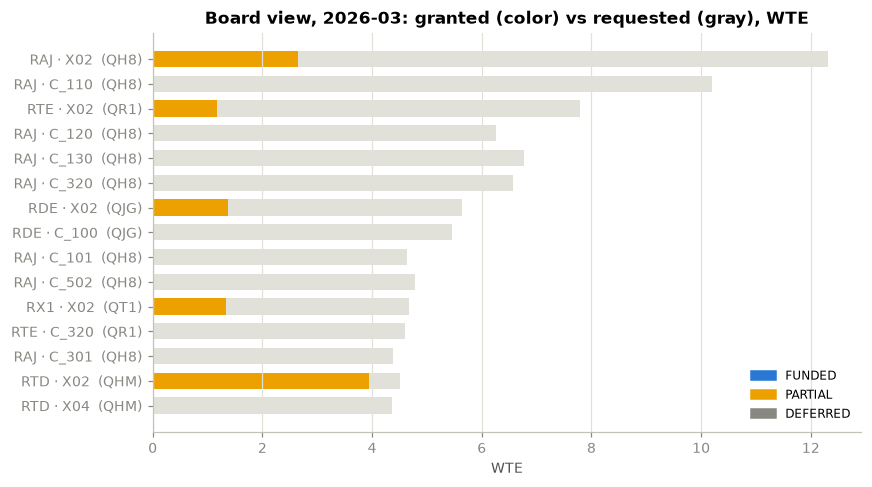

In [3]:
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
})
top = board.head(15).iloc[::-1]
labels = top["provider_code"] + " · " + top["specialty_code"] + "  (" + top["icb"] + ")"
colors = top["status"].map({"FUNDED": "#2a78d6", "PARTIAL": "#eda100", "DEFERRED": "#898781"})
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(labels, top["gap"] / SLOTS_PER_WTE, color="#e1e0d9", height=0.65)
ax.barh(labels, top["granted"] / SLOTS_PER_WTE, color=colors, height=0.65)
ax.set_title(f"Board view, {months[-1]}: granted (color) vs requested (gray), WTE")
ax.set_xlabel("WTE")
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#2a78d6", "#eda100", "#898781"]],
          labels=["FUNDED", "PARTIAL", "DEFERRED"], frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()